# Survey analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from google.colab import files

uploaded = files.upload()
input_file = next(iter(uploaded))
data = pd.read_excel(input_file)
print('Loaded:', input_file)
print('Number of responses:', len(data))

Saving cleaned_survey_data.xlsx to cleaned_survey_data.xlsx
Loaded: cleaned_survey_data.xlsx
Number of responses: 10


## Choose the two survey questions

These column names come from the Google Forms export. The scores at the start of each response (for example, `5 - Daily Power user`) are converted to numbers for analysis.

In [2]:
use_column = 'How frequently do you use AI or Large Language Models (LLMs) in your daily life?'
impact_column = 'How do you perceive the overall impact of LLM usage on your deep conceptual understanding of the subjects or topics you study?'

# Take the number before the dash in each answer and convert it to a number.
data['AI_use_score'] = pd.to_numeric(
    data[use_column].astype(str).str.split('-').str[0].str.strip(), errors='coerce'
)
data['perceived_impact_score'] = pd.to_numeric(
    data[impact_column].astype(str).str.split('-').str[0].str.strip(), errors='coerce'
)

# Use responses that have both scores for the correlation analysis.
analysis_data = data[['AI_use_score', 'perceived_impact_score']].dropna()
print('Responses with both answers:', len(analysis_data))

Responses with both answers: 10


## Descriptive statistics

The frequency tables show how many students selected each response. The summary table gives the count, average, and spread of the numeric scores.

In [3]:
print('AI use frequency (1 = never, 5 = daily):')
print(data['AI_use_score'].value_counts().sort_index())

print('\nPerceived impact on understanding (1 = highly negative, 5 = highly positive):')
print(data['perceived_impact_score'].value_counts().sort_index())

print('\nSummary statistics:')
print(analysis_data.describe().round(2))

AI use frequency (1 = never, 5 = daily):
AI_use_score
1    3
3    2
4    3
5    2
Name: count, dtype: int64

Perceived impact on understanding (1 = highly negative, 5 = highly positive):
perceived_impact_score
1    3
2    2
3    2
4    2
5    1
Name: count, dtype: int64

Summary statistics:
       AI_use_score  perceived_impact_score
count          10.0                   10.00
mean            3.1                    2.60
std             1.6                    1.43
min             1.0                    1.00
25%             1.5                    1.25
50%             3.5                    2.50
75%             4.0                    3.75
max             5.0                    5.00


## Charts

The bar charts show response counts for each scale. The scatter plot shows the two scores for each response.

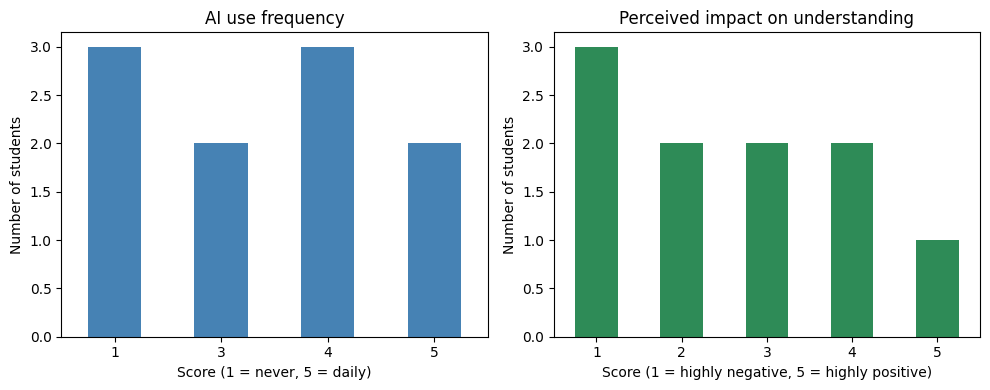

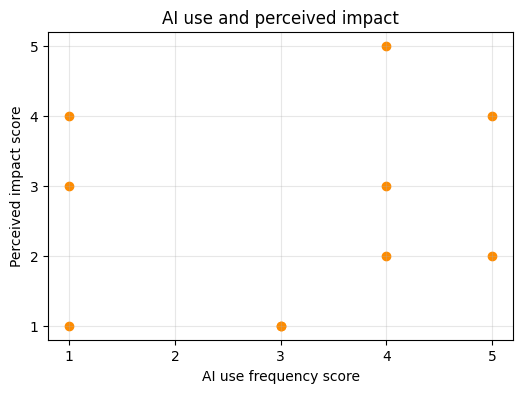

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

data['AI_use_score'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('AI use frequency')
axes[0].set_xlabel('Score (1 = never, 5 = daily)')
axes[0].set_ylabel('Number of students')
axes[0].tick_params(axis='x', rotation=0)

data['perceived_impact_score'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Perceived impact on understanding')
axes[1].set_xlabel('Score (1 = highly negative, 5 = highly positive)')
axes[1].set_ylabel('Number of students')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(analysis_data['AI_use_score'], analysis_data['perceived_impact_score'], color='darkorange')
plt.title('AI use and perceived impact')
plt.xlabel('AI use frequency score')
plt.ylabel('Perceived impact score')
plt.xticks([1, 2, 3, 4, 5])
plt.yticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.show()

## Inferential analysis: Spearman correlation

Spearman correlation checks whether higher AI use scores tend to go together with higher perceived impact scores. The p-value is a common statistical check; with a small survey sample, interpret it cautiously. The result describes an association and does not prove cause and effect.

In [5]:
if len(analysis_data) >= 3:
    correlation, p_value = spearmanr(
        analysis_data['AI_use_score'], analysis_data['perceived_impact_score']
    )
    print(f'Spearman correlation: {correlation:.2f}')
    print(f'p-value: {p_value:.3f}')
    if p_value < 0.05:
        print('This sample shows evidence of an association at the 0.05 level.')
    else:
        print('This sample does not show clear evidence of an association at the 0.05 level.')
else:
    print('At least 3 complete responses are needed for this correlation test.')

Spearman correlation: 0.26
p-value: 0.476
This sample does not show clear evidence of an association at the 0.05 level.
